<a href="https://colab.research.google.com/github/Amukta2906/Bioinformatics-/blob/main/Baseline_and_Classweight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: download and parse

In [1]:
!wget -q https://ftp.ncbi.nlm.nih.gov/geo/series/GSE66nnn/GSE66099/matrix/GSE66099_series_matrix.txt.gz
import gzip, io, pandas as pd, numpy as np

meta_lines, table_lines, in_table = [], [], False
with gzip.open('GSE66099_series_matrix.txt.gz', 'rt') as f:
    for line in f:
        if line.startswith('!series_matrix_table_begin'): in_table = True; continue
        if line.startswith('!series_matrix_table_end'): break
        (table_lines if in_table else meta_lines).append(line)

expr = pd.read_csv(io.StringIO(''.join(table_lines)), sep='\t', index_col=0)
print('Expression:', expr.shape, '(probes x samples)')

Expression: (54675, 276) (probes x samples)


Cell 2: clinical labels

In [2]:
chars = [l.rstrip('\n').split('\t')[1:] for l in meta_lines if l.startswith('!Sample_characteristics_ch1')]
meta = {}
for row in chars:
    for i, v in enumerate(row):
        v = v.strip('"')
        if ': ' in v:
            k, val = v.split(': ', 1)
            meta.setdefault(k, [None]*len(row))[i] = val
meta = pd.DataFrame(meta, index=expr.columns)

for c in meta.columns:
    print(f'\n--- {c} ---'); print(meta[c].value_counts(dropna=False).head(10))


--- tissue ---
tissue
whole blood    276
Name: count, dtype: int64

--- icu_day ---
icu_day
1    276
Name: count, dtype: int64

--- disease ---
disease
SepticShock    181
Control         47
SIRS            30
Sepsis          18
Name: count, dtype: int64


In [3]:
from IPython.display import display

# --- Study-level info (from GEO header) ---
def series_field(tag):
    return [l.split('\t', 1)[1].strip().strip('"') for l in meta_lines if l.startswith(tag)]

print('Title:   ', series_field('!Series_title')[0])
print('Platform:', series_field('!Series_platform_id')[0])
print('Design:  ', ' '.join(series_field('!Series_overall_design'))[:500])
print('Summary: ', ' '.join(series_field('!Series_summary'))[:500])

# --- Shape ---
print(f'\nExpression matrix: {expr.shape[0]:,} probes x {expr.shape[1]} samples')
print(f'Clinical metadata: {meta.shape[0]} samples x {meta.shape[1]} variables')

# --- Head ---
print('\nExpression (first 5 probes x 5 samples):')
display(expr.iloc[:5, :5])
print('\nClinical metadata (first 5 samples):')
display(meta.head())

# --- Summary stats ---
print('\nExpression value summary (all probes, all samples):')
display(pd.Series(expr.values.ravel()).describe().round(2).to_frame('value'))

# --- Missing values ---
print(f'\nMissing expression values: {expr.isna().sum().sum()}')
print('Missing clinical values per column:')
display(meta.isna().sum().to_frame('missing'))

# --- Class counts for each clinical variable ---
for c in meta.columns:
    if meta[c].nunique() <= 10:
        print(f'\n{c}:'); display(meta[c].value_counts(dropna=False).to_frame('n'))

Title:    Unique Patients from the Genomics of Pediatric SIRS and Septic Shock Investigators (GPSSSI)
Platform: GPL570
Design:   The original studies examined pediatric patients admitted to the ICU, who were later classified as either SIRS (non-infectious) or Sepsis or Septic Shock (infectious). There is also a group of healthy controls. Although the original studies examine patients at both ICU day 1 and ICU day 3, here we have only aggregated ICU day 1 patients. All samples here were downloaded as .CEL files and re-normalized together using gcRMA using R package 'affy'.  The normalized data can be found on the series re
Summary:  This dataset is composed of the unique patients (276; at the Day 1 timepoint) that are present in the six other GEO datasets published by Hector Wong and the Genomics of Pediatric SIRS and Septic Shock Investigators. This dataset thus includes all unique patients from GSE4607, GSE8121, GSE9692, GSE13904, GSE26378, and GSE26440. These are only from the Day 1 

,GSM1617492,GSM1617493,GSM1617494,GSM1617495,GSM1617496
ID_REF,,,,,
1007_s_at,2.738883,2.614361,2.628661,2.927789,3.552834
1053_at,4.337271,4.299319,4.655874,4.455195,3.898490
117_at,7.113597,8.176610,9.056479,7.415375,5.398259
121_at,3.665106,3.517643,2.967482,2.893377,3.073314
1255_g_at,1.781134,1.901917,1.526368,1.922836,1.875262



Clinical metadata (first 5 samples):


,tissue,icu_day,disease
GSM1617492,whole blood,1,Control
GSM1617493,whole blood,1,Control
GSM1617494,whole blood,1,Control
GSM1617495,whole blood,1,Control
GSM1617496,whole blood,1,Control



Expression value summary (all probes, all samples):


,value
count,15090300.00
mean,3.55
std,2.32
min,0.14
25%,1.99
50%,2.61
75%,4.29
max,14.93


... (4 outputs left out)


icu_day:


,n
icu_day,
1,276



disease:


,n
disease,
SepticShock,181
Control,47
SIRS,30
Sepsis,18


Cell 3: quick EDA

Value range: 0.14 to 14.93


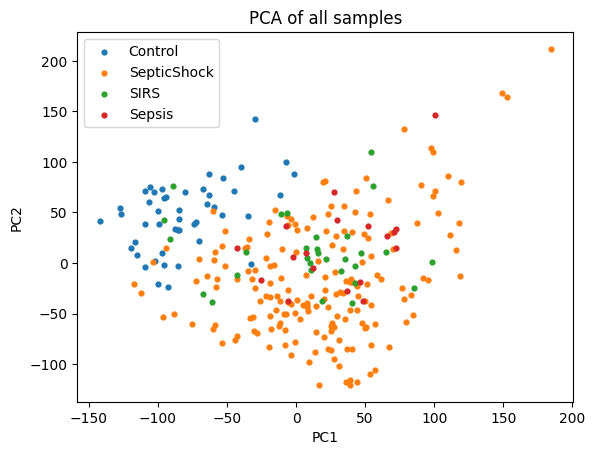

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

print('Value range:', expr.values.min().round(2), 'to', expr.values.max().round(2))
if expr.values.max() > 100:            # not log-scaled yet
    expr = np.log2(expr.clip(lower=1))

LABEL = 'disease'                 # <-- change to the column name from Cell 2
X_all = expr.T
pcs = PCA(2).fit_transform(X_all - X_all.mean())
for g in meta[LABEL].unique():
    m = meta[LABEL] == g
    plt.scatter(pcs[m, 0], pcs[m, 1], label=g, s=12)
plt.legend(); plt.title('PCA of all samples'); plt.xlabel('PC1'); plt.ylabel('PC2'); plt.show()

Cell 4: baseline classifier

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

POS = 'SepticShock'                     # <-- class to predict (e.g., SepticShock from 'disease')
OUTCOME = 'disease'                     # <-- column name from Cell 2
keep = meta[OUTCOME].notna()
X, y = expr.T[keep].values, (meta.loc[keep, OUTCOME] == POS).astype(int).values
print(len(y), 'samples |', y.sum(), 'positive')

cv = StratifiedKFold(5, shuffle=True, random_state=0)
models = {
    'Dummy (baseline)': DummyClassifier(strategy='most_frequent'),
    'LogReg, top 500 genes': make_pipeline(StandardScaler(), SelectKBest(f_classif, k=500),
                                           LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000)),
}
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=['roc_auc', 'balanced_accuracy'])
    print(f"{name:25s} AUC={r['test_roc_auc'].mean():.2f}  bal_acc={r['test_balanced_accuracy'].mean():.2f}")

276 samples | 181 positive
Dummy (baseline)          AUC=0.50  bal_acc=0.50
LogReg, top 500 genes     AUC=0.91  bal_acc=0.80


Logistic regression, top 500 probes, 5-fold CV (pooled out-of-fold predictions)



,Balanced acc,Macro F1,Recall: Healthy,Recall: SIRS,Recall: Infection
Model,,,,,
"LogReg, no class weights",0.66,0.65,0.98,0.07,0.94
"LogReg, class-weighted",0.75,0.74,0.98,0.37,0.90



=== No class weights ===
              precision    recall  f1-score   support

     Healthy       0.94      0.98      0.96        47
        SIRS       0.15      0.07      0.09        30
   Infection       0.88      0.94      0.91       199

    accuracy                           0.86       276
   macro avg       0.66      0.66      0.65       276
weighted avg       0.81      0.86      0.83       276


=== Class-weighted ===
              precision    recall  f1-score   support

     Healthy       0.92      0.98      0.95        47
        SIRS       0.38      0.37      0.37        30
   Infection       0.91      0.90      0.91       199

    accuracy                           0.86       276
   macro avg       0.74      0.75      0.74       276
weighted avg       0.86      0.86      0.86       276



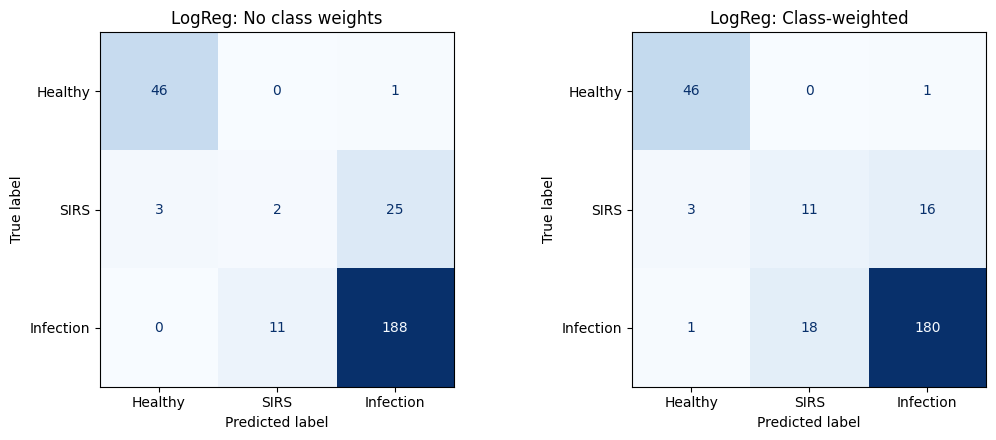

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

# --- Same setup as the Cell 7 baseline ---
label_map = {'Control': 'Healthy', 'SIRS': 'SIRS', 'Sepsis': 'Infection', 'SepticShock': 'Infection'}
y_lr = meta['disease'].map(label_map).values
X_lr = expr.T.values
lr_classes = ['Healthy', 'SIRS', 'Infection']
cv_lr = StratifiedKFold(5, shuffle=True, random_state=0)

def lr_model(weights):
    return make_pipeline(StandardScaler(), SelectKBest(f_classif, k=500),
                         LogisticRegression(C=0.1, class_weight=weights, max_iter=5000))

pred_noW = cross_val_predict(lr_model(None),       X_lr, y_lr, cv=cv_lr)
pred_W   = cross_val_predict(lr_model('balanced'), X_lr, y_lr, cv=cv_lr)

# --- Comparison table ---
def summarize(name, pred):
    rec = recall_score(y_lr, pred, labels=lr_classes, average=None)
    return {'Model': name,
            'Balanced acc': balanced_accuracy_score(y_lr, pred),
            'Macro F1': f1_score(y_lr, pred, average='macro'),
            **{f'Recall: {c}': r for c, r in zip(lr_classes, rec)}}

lr_results = pd.DataFrame([summarize('LogReg, no class weights', pred_noW),
                           summarize('LogReg, class-weighted',  pred_W)]).set_index('Model').round(2)
print('Logistic regression, top 500 probes, 5-fold CV (pooled out-of-fold predictions)\n')
display(lr_results)

# --- Per-class reports ---
for name, pred in [('No class weights', pred_noW), ('Class-weighted', pred_W)]:
    print(f'\n=== {name} ===')
    print(classification_report(y_lr, pred, labels=lr_classes, digits=2))

# --- Confusion matrices side by side ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [('No class weights', pred_noW), ('Class-weighted', pred_W)]):
    ConfusionMatrixDisplay(confusion_matrix(y_lr, pred, labels=lr_classes),
                           display_labels=lr_classes).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'LogReg: {name}')
plt.tight_layout(); plt.show()

In [6]:
from IPython.display import display

# --- Study-level info (from GEO header) ---
def series_field(tag):
    return [l.split('\t', 1)[1].strip().strip('"') for l in meta_lines if l.startswith(tag)]

print('Title:   ', series_field('!Series_title')[0])
print('Platform:', series_field('!Series_platform_id')[0])
print('Design:  ', ' '.join(series_field('!Series_overall_design'))[:500])
print('Summary: ', ' '.join(series_field('!Series_summary'))[:500])

# --- Shape ---
print(f'\nExpression matrix: {expr.shape[0]:,} probes x {expr.shape[1]} samples')
print(f'Clinical metadata: {meta.shape[0]} samples x {meta.shape[1]} variables')

# --- Head ---
print('\nExpression (first 5 probes x 5 samples):')
display(expr.iloc[:5, :5])
print('\nClinical metadata (first 5 samples):')
display(meta.head())

# --- Summary stats ---
print('\nExpression value summary (all probes, all samples):')
display(pd.Series(expr.values.ravel()).describe().round(2).to_frame('value'))

# --- Missing values ---
print(f'\nMissing expression values: {expr.isna().sum().sum()}')
print('Missing clinical values per column:')
display(meta.isna().sum().to_frame('missing'))

# --- Class counts for each clinical variable ---
for c in meta.columns:
    if meta[c].nunique() <= 10:
        print(f'\n{c}:'); display(meta[c].value_counts(dropna=False).to_frame('n'))

Title:    Unique Patients from the Genomics of Pediatric SIRS and Septic Shock Investigators (GPSSSI)
Platform: GPL570
Design:   The original studies examined pediatric patients admitted to the ICU, who were later classified as either SIRS (non-infectious) or Sepsis or Septic Shock (infectious). There is also a group of healthy controls. Although the original studies examine patients at both ICU day 1 and ICU day 3, here we have only aggregated ICU day 1 patients. All samples here were downloaded as .CEL files and re-normalized together using gcRMA using R package 'affy'.  The normalized data can be found on the series re
Summary:  This dataset is composed of the unique patients (276; at the Day 1 timepoint) that are present in the six other GEO datasets published by Hector Wong and the Genomics of Pediatric SIRS and Septic Shock Investigators. This dataset thus includes all unique patients from GSE4607, GSE8121, GSE9692, GSE13904, GSE26378, and GSE26440. These are only from the Day 1 

,GSM1617492,GSM1617493,GSM1617494,GSM1617495,GSM1617496
ID_REF,,,,,
1007_s_at,2.738883,2.614361,2.628661,2.927789,3.552834
1053_at,4.337271,4.299319,4.655874,4.455195,3.898490
117_at,7.113597,8.176610,9.056479,7.415375,5.398259
121_at,3.665106,3.517643,2.967482,2.893377,3.073314
1255_g_at,1.781134,1.901917,1.526368,1.922836,1.875262



Clinical metadata (first 5 samples):


,tissue,icu_day,disease
GSM1617492,whole blood,1,Control
GSM1617493,whole blood,1,Control
GSM1617494,whole blood,1,Control
GSM1617495,whole blood,1,Control
GSM1617496,whole blood,1,Control



Expression value summary (all probes, all samples):


,value
count,15090300.00
mean,3.55
std,2.32
min,0.14
25%,1.99
50%,2.61
75%,4.29
max,14.93


... (4 outputs left out)


icu_day:


,n
icu_day,
1,276



disease:


,n
disease,
SepticShock,181
Control,47
SIRS,30
Sepsis,18


Infection    199
Healthy       47
SIRS          30
Name: count, dtype: int64
Dummy (majority)          macro AUC=0.50 ± 0.00  bal_acc=0.33
LogReg, top 500 genes     macro AUC=0.91 ± 0.05  bal_acc=0.75

               precision    recall  f1-score   support

     Healthy       0.92      0.98      0.95        47
        SIRS       0.38      0.37      0.37        30
   Infection       0.91      0.90      0.91       199

    accuracy                           0.86       276
   macro avg       0.74      0.75      0.74       276
weighted avg       0.86      0.86      0.86       276



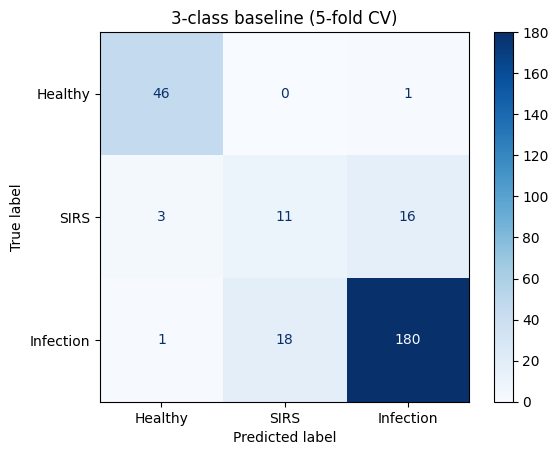

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# --- 3-class labels ---
label_map = {'Control': 'Healthy', 'SIRS': 'SIRS', 'Sepsis': 'Infection', 'SepticShock': 'Infection'}
y3 = meta['disease'].map(label_map).values
X3 = expr.T.values
classes = ['Healthy', 'SIRS', 'Infection']
print(pd.Series(y3).value_counts())

cv = StratifiedKFold(5, shuffle=True, random_state=0)
models = {
    'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
    'LogReg, top 500 genes': make_pipeline(
        StandardScaler(), SelectKBest(f_classif, k=500),
        LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000)),
}

# --- Scores ---
for name, m in models.items():
    r = cross_validate(m, X3, y3, cv=cv, scoring=['roc_auc_ovr', 'balanced_accuracy'])
    print(f"{name:25s} macro AUC={r['test_roc_auc_ovr'].mean():.2f} ± {r['test_roc_auc_ovr'].std():.2f}"
          f"  bal_acc={r['test_balanced_accuracy'].mean():.2f}")

# --- Per-class results + confusion matrix (LogReg) ---
pred = cross_val_predict(models['LogReg, top 500 genes'], X3, y3, cv=cv)
print('\n', classification_report(y3, pred, labels=classes, digits=2))
ConfusionMatrixDisplay(confusion_matrix(y3, pred, labels=classes), display_labels=classes).plot(cmap='Blues')
plt.title('3-class baseline (5-fold CV)'); plt.show()

Cell 8: map probes to genes

In [8]:
!wget -q https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz && ls -lh GPL570.annot.gz
with gzip.open('GPL570.annot.gz', 'rt') as f:
    lines = f.readlines()
s = next(i for i, l in enumerate(lines) if l.startswith('!platform_table_begin')) + 1
e = next(i for i, l in enumerate(lines) if l.startswith('!platform_table_end'))
annot = pd.read_csv(io.StringIO(''.join(lines[s:e])), sep='\t', usecols=['ID', 'Gene symbol']).dropna()
annot = annot[~annot['Gene symbol'].str.contains('///')]        # drop probes hitting multiple genes

g = expr.loc[expr.index.intersection(annot['ID'])].copy()
g['gene'] = annot.set_index('ID').loc[g.index, 'Gene symbol'].values
g['mean'] = g.drop(columns='gene').mean(axis=1)
gene_expr = (g.sort_values('mean', ascending=False)
              .drop_duplicates('gene').set_index('gene').drop(columns='mean').T)   # patients x genes
print('Gene matrix:', gene_expr.shape)

-rw-r--r-- 1 root root 8.1M Aug 22  2016 GPL570.annot.gz
Gene matrix: (276, 20848)


Cell 9: XGBoost + SHAP panels

In [9]:
!pip -q install xgboost shap
import numpy as np, pandas as pd, shap, matplotlib.pyplot as plt
from collections import Counter
from xgboost import XGBClassifier
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight

Xg = gene_expr
label_map = {'Control': 'Healthy', 'SIRS': 'SIRS', 'Sepsis': 'Infection', 'SepticShock': 'Infection'}
le = LabelEncoder().fit(['Healthy', 'SIRS', 'Infection'])
y = le.transform(meta.loc[Xg.index, 'disease'].map(label_map))
classes = le.classes_
X, genes = Xg.values, np.array(Xg.columns)

KS = [5, 10, 20, 50]
oof_xgb = np.zeros(len(y), int)
oof_panel = {k: np.zeros(len(y), int) for k in KS}
picked = {k: Counter() for k in KS}
cv = StratifiedKFold(5, shuffle=True, random_state=42)

for fold, (tr, te) in enumerate(cv.split(X, y), 1):
    # 1. F-test filter (training fold only)
    F, _ = f_classif(X[tr], y[tr])
    top = np.argsort(np.nan_to_num(F))[::-1][:2000]

    # 2. XGBoost, class-weighted
    xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.3, eval_metric='mlogloss', random_state=42, n_jobs=-1)
    xgb.fit(X[tr][:, top], y[tr], sample_weight=compute_sample_weight('balanced', y[tr]))
    oof_xgb[te] = xgb.predict(X[te][:, top])

    # 3. SHAP ranking (training fold only)
    sv = shap.TreeExplainer(xgb).shap_values(X[tr][:, top])
    sv = np.stack(sv, -1) if isinstance(sv, list) else sv
    ranked = top[np.argsort(np.abs(sv).mean(axis=(0, 2)))[::-1]]

    # 4. Small gene panels -> logistic regression
    for k in KS:
        idx = ranked[:k]
        picked[k].update(genes[idx])
        sc = StandardScaler().fit(X[tr][:, idx])
        lr = LogisticRegression(class_weight='balanced', max_iter=5000).fit(sc.transform(X[tr][:, idx]), y[tr])
        oof_panel[k][te] = lr.predict(sc.transform(X[te][:, idx]))
    print(f'fold {fold} done')

fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done


Cell 10: results

XGBoost, top 2,000 genes, 5-fold CV (pooled out-of-fold predictions)



,Balanced acc,Macro F1,Recall: Healthy,Recall: Infection,Recall: SIRS
Model,,,,,
"XGBoost, no class weights",0.68,0.66,0.98,0.98,0.07
"XGBoost, class-weighted",0.69,0.68,1.00,0.94,0.13



=== No class weights ===
              precision    recall  f1-score   support

     Healthy       0.92      0.98      0.95        47
   Infection       0.88      0.98      0.93       199
        SIRS       0.40      0.07      0.11        30

    accuracy                           0.88       276
   macro avg       0.73      0.68      0.66       276
weighted avg       0.84      0.88      0.84       276


=== Class-weighted ===
              precision    recall  f1-score   support

     Healthy       0.89      1.00      0.94        47
   Infection       0.90      0.94      0.92       199
        SIRS       0.31      0.13      0.19        30

    accuracy                           0.87       276
   macro avg       0.70      0.69      0.68       276
weighted avg       0.83      0.87      0.84       276



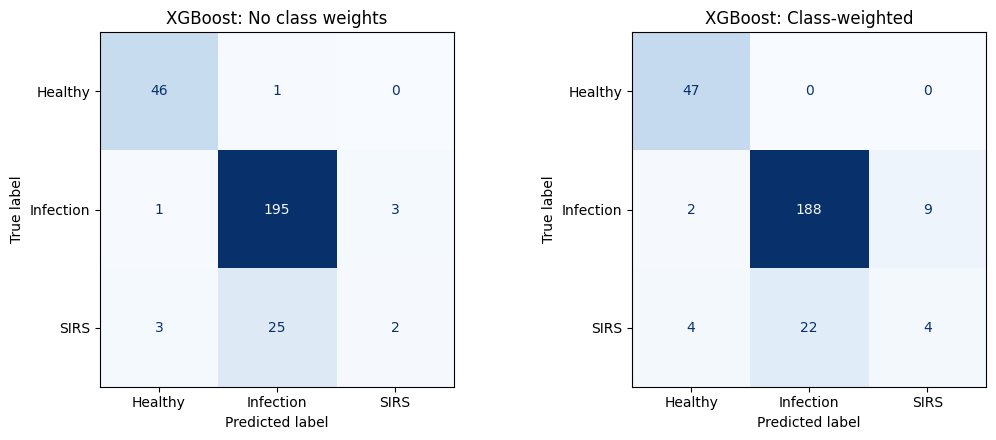

In [13]:
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

# --- XGBoost without class weights (same folds, same top-2000 genes) ---
oof_xgb_noW = np.zeros(len(y), int)
for tr, te in cv.split(X, y):
    F, _ = f_classif(X[tr], y[tr])
    top = np.argsort(np.nan_to_num(F))[::-1][:2000]
    m = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.3, eval_metric='mlogloss', random_state=42, n_jobs=-1)
    m.fit(X[tr][:, top], y[tr])
    oof_xgb_noW[te] = m.predict(X[te][:, top])

# --- Comparison table ---
def summarize(name, pred):
    rec = recall_score(y, pred, average=None)
    return {'Model': name,
            'Balanced acc': balanced_accuracy_score(y, pred),
            'Macro F1': f1_score(y, pred, average='macro'),
            **{f'Recall: {c}': r for c, r in zip(classes, rec)}}

results = pd.DataFrame([summarize('XGBoost, no class weights', oof_xgb_noW),
                        summarize('XGBoost, class-weighted',  oof_xgb)]).set_index('Model').round(2)
print('XGBoost, top 2,000 genes, 5-fold CV (pooled out-of-fold predictions)\n')
display(results)

# --- Per-class reports ---
for name, pred in [('No class weights', oof_xgb_noW), ('Class-weighted', oof_xgb)]:
    print(f'\n=== {name} ===')
    print(classification_report(y, pred, target_names=classes, digits=2))

# --- Confusion matrices side by side ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [('No class weights', oof_xgb_noW), ('Class-weighted', oof_xgb)]):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=classes).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'XGBoost: {name}')
plt.tight_layout(); plt.show()